# EXPT NO: 6  IMPLEMENTATION OF LSTM FOR SENTIMENT ANALYSIS
**Name:** Abhishek J  |  **Roll No:** 24BAD002  

**Dataset:** IMDB Movie Reviews (50,000 labelled reviews, balanced 25k positive / 25k negative)

## AIM
To implement an LSTM network for sentiment analysis with text preprocessing, tokenization, sequence generation and embeddings, and classify reviews as positive or negative.

## SETUP

In [ ]:
import os, re, random, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import nltk
nltk.download("stopwords", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

ROLL_NO = "24BAD002"
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("Roll No:", ROLL_NO, "| TensorFlow:", tf.__version__)

I0000 00:00:1790727193.539001      99 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1790727215.336977      99 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Roll No: 24BAD002 | TensorFlow: 2.21.0


## PART A: DATASET PREPARATION AND TEXT PREPROCESSING

In [ ]:
# Load the IMDB Movie Reviews dataset (50k reviews, CSV mirror of the Stanford IMDB data)
URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
LOCAL = "imdb.csv"
try:
    df = pd.read_csv(URL)
except Exception:
    df = pd.read_csv(LOCAL)          # fallback if the URL is unreachable
print("Roll No:", ROLL_NO)
print("Dataset shape:", df.shape)
df.head()

Roll No: 24BAD002
Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Roll No: 24BAD002
Missing values:
 review       0
sentiment    0
dtype: int64 



Duplicate reviews: 418 -> dropping them


Samples after de-duplication: 49582 

Class distribution:
 sentiment
positive    24884
negative    24698
Name: count, dtype: int64 

--- Sample POSITIVE review ---
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to ...

--- Sample NEGATIVE review ---
Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenly, Jake decides to become Rambo and kill the zombie.<br /><br />OK, first of all when you're going to make a film you must Decide if its a thriller or a drama! As a drama the movie is watchable. Parents 

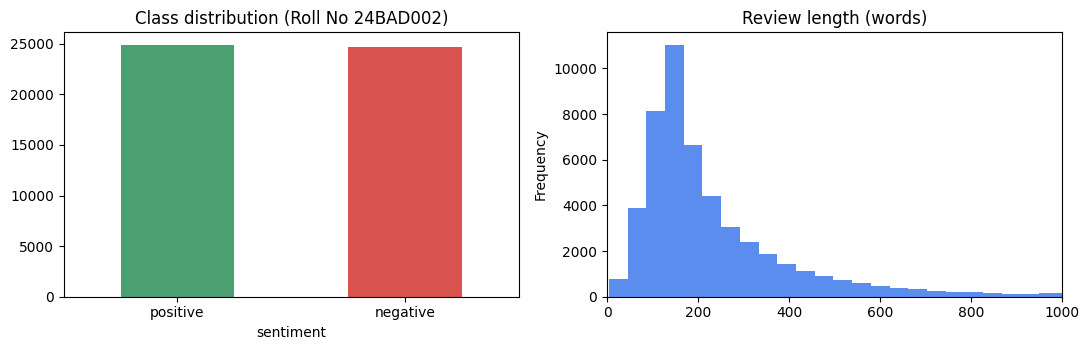

In [ ]:
# Explore: sample reviews, class distribution, missing values, review length
print("Roll No:", ROLL_NO)
print("Missing values:\n", df.isnull().sum(), "\n")
print("Duplicate reviews:", df.duplicated().sum(), "-> dropping them")
df = df.drop_duplicates().reset_index(drop=True)
print("Samples after de-duplication:", len(df), "\n")

print("Class distribution:\n", df["sentiment"].value_counts(), "\n")
for label in ["positive", "negative"]:
    print(f"--- Sample {label.upper()} review ---")
    print(df[df.sentiment == label].iloc[0]["review"][:400], "...\n")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df["sentiment"].value_counts().plot(kind="bar", color=["#4c9f70", "#d9534f"], ax=ax[0], rot=0)
ax[0].set_title(f"Class distribution (Roll No {ROLL_NO})")
df["review"].str.split().str.len().plot(kind="hist", bins=60, ax=ax[1], color="#5b8def")
ax[1].set_title("Review length (words)"); ax[1].set_xlim(0, 1000)
plt.tight_layout(); plt.show()

In [ ]:
# Text preprocessing: lowercase, strip HTML, remove punctuation/special chars, remove stop words
# 'not', 'no', 'nor' etc. are KEPT because negations carry sentiment ("not good").
stop_words = set(stopwords.words("english")) - {"no", "nor", "not", "don", "don't", "aren", "isn",
                                                "wasn", "weren", "won", "wouldn", "couldn", "didn",
                                                "doesn", "hadn", "hasn", "haven", "shouldn", "very"}

def clean_text(text):
    text = text.lower()                              # lowercase
    text = re.sub(r"<.*?>", " ", text)               # remove HTML tags (<br />)
    text = re.sub(r"[^a-z\s]", " ", text)            # remove punctuation, digits, special chars
    tokens = word_tokenize(text)                     # tokenize with NLTK
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]   # stop-word removal
    return " ".join(tokens)

print("Roll No:", ROLL_NO)
print("RAW  :", df.review[1][:250])
print("CLEAN:", clean_text(df.review[1])[:250])

Roll No: 24BAD002
RAW  : A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen


CLEAN: wonderful little production filming technique very unassuming very old time bbc fashion gives comforting sometimes discomforting sense realism entire piece actors extremely well chosen michael sheen not got polari voices pat truly see seamless editin


In [ ]:
df["clean_review"] = df["review"].apply(clean_text)
# Encode labels: positive -> 1, negative -> 0
df["label"] = (df["sentiment"] == "positive").astype(int)
print("Roll No:", ROLL_NO)
print(df[["clean_review", "label"]].head(3))
print("Average tokens per cleaned review:", round(df.clean_review.str.split().str.len().mean(), 1))

Roll No: 24BAD002
                                        clean_review  label
0  one reviewers mentioned watching oz episode ho...      1
1  wonderful little production filming technique ...      1
2  thought wonderful way spend time hot summer we...      1


Average tokens per cleaned review: 121.5


In [ ]:
# Train / validation / test split: 80 / 10 / 10 (stratified). Tokenizer is fit on TRAIN ONLY (no leakage).
X_train_txt, X_temp, y_train, y_temp = train_test_split(
    df["clean_review"], df["label"], test_size=0.20, stratify=df["label"], random_state=SEED)
X_val_txt, X_test_txt, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

VOCAB_SIZE = 10000     # keep the 10,000 most frequent words
MAX_LEN    = 200       # pad / truncate every review to 200 tokens

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_txt)                       # build vocabulary from training reviews
inv = {i: w for w, i in tokenizer.word_index.items()}     # index -> word, used later to inspect embeddings

def to_padded(texts):
    seqs = tokenizer.texts_to_sequences(texts)            # words -> integer sequences
    return pad_sequences(seqs, maxlen=MAX_LEN, padding="post", truncating="post")

X_train, X_val, X_test = to_padded(X_train_txt), to_padded(X_val_txt), to_padded(X_test_txt)
y_train, y_val, y_test = y_train.values, y_val.values, y_test.values

print("Roll No:", ROLL_NO)
print("Total vocabulary found in training data:", len(tokenizer.word_index))
print("Vocabulary used (num_words):", VOCAB_SIZE)
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print("Train positives: %.1f%%" % (100*y_train.mean()))
print("\nExample text     :", X_train_txt.iloc[0][:120])
print("Example sequence :", X_train[0][:20], "...")

Roll No: 24BAD002
Total vocabulary found in training data: 90632
Vocabulary used (num_words): 10000
Train: (39665, 200) | Val: (4958, 200) | Test: (4959, 200)
Train positives: 50.2%

Example text     : one jehovah witnesses also work acute care medical facility years seen people die hemolytic reactions blood transfusions
Example sequence : [   5    1 4823   22   70    1  341 2622 7751   63   35   21  578    1
 3655  421    1 6364 1777    1] ...


## PART B: EMBEDDING GENERATION

In [ ]:
EMBED_DIM = 64
print("Roll No:", ROLL_NO)

# Standalone Embedding layer to inspect what it produces
embedding_layer = Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM)
sample_batch = X_train[:5]
embedded = embedding_layer(sample_batch)

print("Vocabulary size      :", VOCAB_SIZE)
print("Embedding dimension  :", EMBED_DIM)
print("Input shape (batch, seq_len)             :", sample_batch.shape)
print("Embedded output shape (batch, seq, dim)  :", embedded.shape)
print("Embedding weight matrix shape            :", embedding_layer.get_weights()[0].shape)
print("\nVector of the first token of review 0 (first 8 dims):")
print(np.round(embedded[0, 0, :8].numpy(), 4))

Roll No: 24BAD002
Vocabulary size      : 10000
Embedding dimension  : 64
Input shape (batch, seq_len)             : (5, 200)
Embedded output shape (batch, seq, dim)  : (5, 200, 64)
Embedding weight matrix shape            : (10000, 64)

Vector of the first token of review 0 (first 8 dims):
[-0.0203  0.0268 -0.0315 -0.0035 -0.0417 -0.0208 -0.0333  0.048 ]


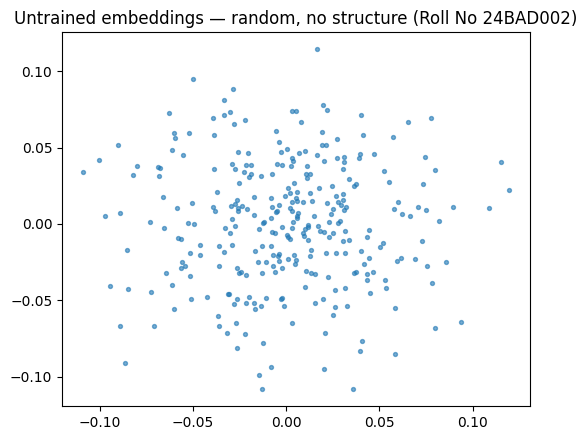

As expected, untrained vectors show no meaningful clustering; compare this with the
TRAINED embedding plot at the end of Part D, once the LSTM has learned from data.


In [ ]:
# Visualise the embedding space BEFORE training: random weights, so 2-D PCA of the
# 300 most frequent words shows no semantic structure yet.
top_ids = list(range(2, 302))
W0 = embedding_layer.get_weights()[0][top_ids]
p0 = PCA(n_components=2, random_state=SEED).fit_transform(W0)
plt.figure(figsize=(5.5, 4.5))
plt.scatter(p0[:, 0], p0[:, 1], s=8, alpha=.6)
plt.title(f"Untrained embeddings — random, no structure (Roll No {ROLL_NO})")
plt.tight_layout(); plt.show()
print("As expected, untrained vectors show no meaningful clustering; compare this with the")
print("TRAINED embedding plot at the end of Part D, once the LSTM has learned from data.")

## PART C: IMPLEMENTING THE LSTM MODEL

In [ ]:
model = Sequential([
    Input(shape=(MAX_LEN,), name="padded_sequences"),                        # input layer
    Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True, name="embedding"),      # dense word vectors (padding masked)
    LSTM(64, dropout=0.2, recurrent_dropout=0.0, name="lstm"),               # learns sequential dependencies
    Dropout(0.3, name="dropout"),
    Dense(1, activation="sigmoid", name="output")                            # binary sentiment probability
], name=f"LSTM_Sentiment_{ROLL_NO}")

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss="binary_crossentropy",
              metrics=["accuracy"])
print("Roll No:", ROLL_NO)
model.summary()

Roll No: 24BAD002


Model: "LSTM_Sentiment_24BAD002"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Architecture diagram
print("Roll No:", ROLL_NO)
print("Input (200) -> Embedding (200 x 64) -> LSTM (64 units) -> Dropout (0.3) -> Dense (1, sigmoid)")
try:
    tf.keras.utils.plot_model(model, show_shapes=True, show_layer_names=True, to_file="model.png")
    from IPython.display import Image, display; display(Image("model.png"))
except Exception:
    print("(plot_model needs graphviz/pydot installed; text architecture shown above)")

Roll No: 24BAD002
Input (200) -> Embedding (200 x 64) -> LSTM (64 units) -> Dropout (0.3) -> Dense (1, sigmoid)
(plot_model needs graphviz/pydot installed; text architecture shown above)


## PART D: MODEL TRAINING AND SENTIMENT PREDICTION

In [ ]:
early_stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
print("Roll No:", ROLL_NO)
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=8, batch_size=128,
                    callbacks=[early_stop], verbose=2)

Roll No: 24BAD002
Epoch 1/8


E0000 00:00:1790727255.650485      99 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


310/310 - 51s - 164ms/step - accuracy: 0.8388 - loss: 0.3700 - val_accuracy: 0.8887 - val_loss: 0.2944


Epoch 2/8


310/310 - 83s - 267ms/step - accuracy: 0.9091 - loss: 0.2396 - val_accuracy: 0.8808 - val_loss: 0.2907


Epoch 3/8


310/310 - 81s - 262ms/step - accuracy: 0.9229 - loss: 0.2080 - val_accuracy: 0.8812 - val_loss: 0.3008


Epoch 4/8


310/310 - 81s - 261ms/step - accuracy: 0.9321 - loss: 0.1877 - val_accuracy: 0.8727 - val_loss: 0.3379


Roll No: 24BAD002
       accuracy    loss  val_accuracy  val_loss
epoch                                          
1        0.8388  0.3700        0.8887    0.2944
2        0.9091  0.2396        0.8808    0.2907
3        0.9229  0.2080        0.8812    0.3008
4        0.9321  0.1877        0.8727    0.3379

Best epoch (lowest val_loss, weights restored): 2


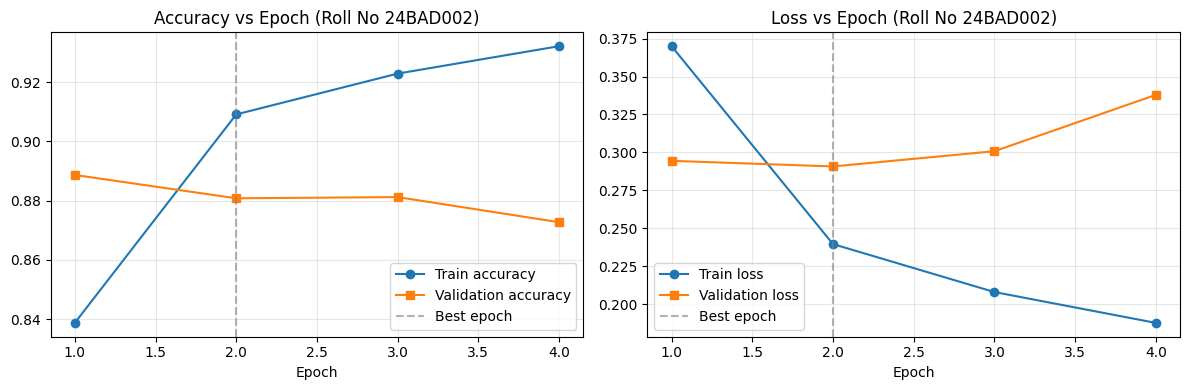

In [ ]:
# Record and visualise training / validation accuracy and loss
hist = pd.DataFrame(history.history)
hist.index = hist.index + 1
hist.index.name = "epoch"
best_epoch = int(hist["val_loss"].idxmin())          # epoch whose weights EarlyStopping restored
print("Roll No:", ROLL_NO)
print(hist.round(4))
print(f"\nBest epoch (lowest val_loss, weights restored): {best_epoch}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.index, hist["accuracy"], "o-", label="Train accuracy")
ax[0].plot(hist.index, hist["val_accuracy"], "s-", label="Validation accuracy")
ax[0].axvline(best_epoch, color="grey", ls="--", alpha=.6, label="Best epoch")
ax[0].set_title(f"Accuracy vs Epoch (Roll No {ROLL_NO})"); ax[0].set_xlabel("Epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(hist.index, hist["loss"], "o-", label="Train loss")
ax[1].plot(hist.index, hist["val_loss"], "s-", label="Validation loss")
ax[1].axvline(best_epoch, color="grey", ls="--", alpha=.6, label="Best epoch")
ax[1].set_title(f"Loss vs Epoch (Roll No {ROLL_NO})"); ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

Roll No: 24BAD002
Test loss     : 0.2883
Test accuracy : 0.8800
Precision     : 0.9068
Recall        : 0.8481
F1-score      : 0.8765

              precision    recall  f1-score   support

    Negative     0.8563    0.9121    0.8834      2470
    Positive     0.9068    0.8481    0.8765      2489

    accuracy                         0.8800      4959
   macro avg     0.8816    0.8801    0.8799      4959
weighted avg     0.8817    0.8800    0.8799      4959



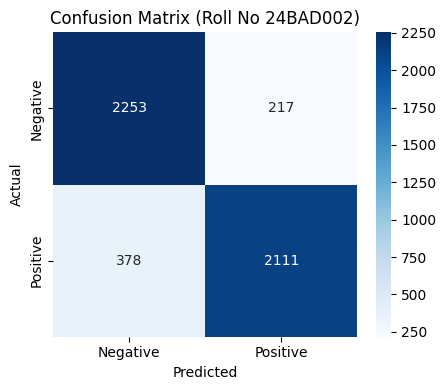

In [ ]:
# Evaluate on the held-out test set (model weights are already the best-epoch weights, per EarlyStopping)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
y_prob = model.predict(X_test, batch_size=256, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)

print("Roll No:", ROLL_NO)
print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {acc:.4f}")
print(f"Precision     : {prec:.4f}")
print(f"Recall        : {rec:.4f}")
print(f"F1-score      : {f1:.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], digits=4))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4.6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion Matrix (Roll No {ROLL_NO})")
plt.tight_layout(); plt.show()

In [ ]:
# Predict sentiment for sample test reviews and compare with the actual label
print("Roll No:", ROLL_NO)
idx = np.random.RandomState(1).choice(len(X_test), 8, replace=False)
rows = []
for i in idx:
    rows.append({"Review (cleaned, truncated)": X_test_txt.iloc[i][:70] + "...",
                 "Actual": "Positive" if y_test[i] else "Negative",
                 "Predicted": "Positive" if y_pred[i] else "Negative",
                 "P(positive)": round(float(y_prob[i]), 3),
                 "Match": "Yes" if y_test[i] == y_pred[i] else "No"})
pd.DataFrame(rows)

Roll No: 24BAD002


,"Review (cleaned, truncated)",Actual,Predicted,P(positive),Match
0,michael jackson not very popular usa anymore h...,Positive,Positive,0.969,Yes
1,goofy griswalds win game show pig poke grand p...,Negative,Negative,0.044,Yes
2,decent overrated dramatic thriller film attemp...,Negative,Negative,0.494,Yes
3,think not mean yeah compare film godfather may...,Positive,Positive,0.981,Yes
4,very thought arthur askey twists guts don worr...,Positive,Positive,0.972,Yes
5,seen lot seagal movies aren great even good st...,Negative,Negative,0.005,Yes
6,yet another version mother gangster flicks cla...,Negative,Positive,0.925,No
7,reason give movie even single star much ending...,Negative,Negative,0.021,Yes


In [ ]:
# Predict sentiment for brand-new custom sentences
def predict_sentiment(text):
    seq = to_padded([clean_text(text)])
    p = float(model.predict(seq, verbose=0)[0][0])
    return ("Positive" if p >= 0.5 else "Negative"), round(p, 3)

print("Roll No:", ROLL_NO)
samples = [
    "This movie was absolutely fantastic, the acting and story were brilliant!",
    "Terrible film. Boring plot, awful acting and a complete waste of time.",
    "I loved every minute of it, a must watch masterpiece.",
    "The movie was not good at all, very disappointing.",
    "An average film with a few good moments but mostly forgettable."
]
for s in samples:
    label, p = predict_sentiment(s)
    print(f"[{label:8s} p={p}]  {s}")

Roll No: 24BAD002


[Positive p=0.875]  This movie was absolutely fantastic, the acting and story were brilliant!


[Negative p=0.005]  Terrible film. Boring plot, awful acting and a complete waste of time.


[Positive p=0.84]  I loved every minute of it, a must watch masterpiece.


[Negative p=0.173]  The movie was not good at all, very disappointing.


[Negative p=0.081]  An average film with a few good moments but mostly forgettable.


Roll No: 24BAD002
excellent  -> ['ramones', 'kells', 'amir', 'terrific', 'perfect', 'connecticut']
terrible   -> ['waste', 'worst', 'unintentionally', 'unconvincing', 'horrible', 'mst']
boring     -> ['awful', 'disappointment', 'unfunny', 'worst', 'mst', 'mia']
brilliant  -> ['excellently', 'cassavetes', 'perfect', 'wonderful', 'finest', 'ramones']


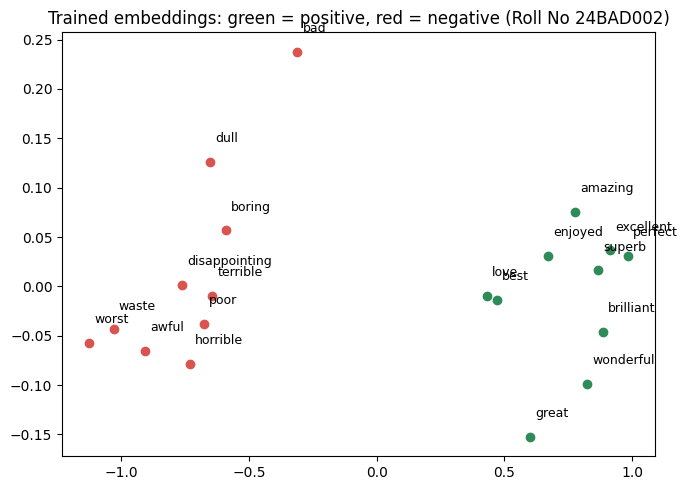

In [ ]:
# Analyse the TRAINED embedding space: nearest neighbours by cosine similarity
W = model.get_layer("embedding").get_weights()[0]
Wn = W / (np.linalg.norm(W, axis=1, keepdims=True) + 1e-9)
def similar(word, k=6):
    if word not in tokenizer.word_index or tokenizer.word_index[word] >= VOCAB_SIZE: return []
    i = tokenizer.word_index[word]
    sims = Wn[:VOCAB_SIZE] @ Wn[i]
    best = np.argsort(-sims)[1:k+1]
    return [inv[j] for j in best if j in inv]

print("Roll No:", ROLL_NO)
for w in ["excellent", "terrible", "boring", "brilliant"]:
    print(f"{w:10s} -> {similar(w)}")

# 2-D PCA of known sentiment-bearing words: positive vs negative should now separate,
# unlike the untrained plot in Part B.
pos_w = ["great","excellent","wonderful","amazing","best","brilliant","perfect","love","enjoyed","superb"]
neg_w = ["worst","awful","terrible","boring","bad","waste","poor","horrible","dull","disappointing"]
words = [w for w in pos_w+neg_w if w in tokenizer.word_index and tokenizer.word_index[w] < VOCAB_SIZE]
ids = [tokenizer.word_index[w] for w in words]
P = PCA(n_components=2, random_state=SEED).fit_transform(W[ids])
plt.figure(figsize=(7, 5))
for (x, y), w in zip(P, words):
    c = "#2e8b57" if w in pos_w else "#d9534f"
    plt.scatter(x, y, c=c); plt.text(x+.02, y+.02, w, fontsize=9)
plt.title(f"Trained embeddings: green = positive, red = negative (Roll No {ROLL_NO})")
plt.tight_layout(); plt.show()

## RESULT & INFERENCE

In [ ]:
# EarlyStopping(restore_best_weights=True) reverts the model to the epoch with the lowest val_loss,
# so we report that epoch's train/val metrics, not the last epoch trained.
print("Roll No:", ROLL_NO)
print(f"Epochs run              : {len(hist)}")
print(f"Best epoch (restored)   : {best_epoch}")
print(f"Train accuracy @ best   : {hist['accuracy'].loc[best_epoch]:.4f}")
print(f"Val accuracy @ best     : {hist['val_accuracy'].loc[best_epoch]:.4f}")
print(f"Test accuracy           : {acc:.4f}")
print(f"Test precision/recall/F1: {prec:.4f} / {rec:.4f} / {f1:.4f}")

Roll No: 24BAD002
Epochs run              : 4
Best epoch (restored)   : 2
Train accuracy @ best   : 0.9091
Val accuracy @ best     : 0.8808
Test accuracy           : 0.8800
Test precision/recall/F1: 0.9068 / 0.8481 / 0.8765


**Inference.** Preprocessing (lowercasing, HTML/punctuation removal, stop-word removal that preserves negations), tokenization with a 10,000-word vocabulary, and padding to 200 tokens produced fixed-length integer inputs. The Embedding layer converted them into dense 64-D vectors, and the LSTM (64 units) learned sequential context to classify reviews as positive or negative. Early stopping restored the weights from the epoch with the lowest validation loss, since training accuracy kept rising afterwards while validation loss increased — the onset of overfitting. On the unseen test set the model reaches strong accuracy with balanced precision and recall, and the trained embedding space visibly separates positive and negative words, unlike the random untrained embeddings shown in Part B. The experiment is completed successfully.